## This is the Data Hygiene Notebook File for Fake Client 2, on the dataset of Cafe Records

This is written so a technical team member can see exactly what happened on the dataset so it can be used for a better understanding of the process or future data processing with this dataset.

### How to use

To properly run or view this file, you will need a application capable of working with Jupyter notebook files (.ipynb files). Below is a listing of a few options you can use.

Option A: Anaconda Distribution  
You can install a free, open source collection of data science coding tools called the Anaconda Distribution from their website: https://www.anaconda.com/download. This includes everything you need to view and run these files. This is the best option if you are planning to do more work with more datasets or are working on this particular file.


Option B: VS Code  
If you prefer another editor, you can install Microsoft's Visual Studio Code along with its Python extensions. Go to https://code.visualstudio.com/download, then download the extensions using by clicking on the extensions button on the left sidebar, (the icon with the 4 squares) and searching up Jupyter Notebook. You will still need Python installed on your computer to run the code, which you can get by going to https://www.python.org/downloads/.  


Option C: Google Colab  
If you do not want to download software to your computer, you can upload the notebook file directly to Google Colab in your web browser https://colab.research.google.com/.

Once you have a proper application, we finally must make sure the project files and extra tools are ready.    
Make sure that the **original data file sent back to you, as listed in this file below, with the exact same name** is in the same file or directory as this file that you're looking at. For example, this file was likely sent to you with a bundle of other files, including the oringal data file that was used here, all in a single folder. As long as this file and the raw data are still in the same folder, this .ipynb file should be able to find it and run properly. If that is not the case, you must find the original and but it back in this folder, or put them together in a new folder. There are other ways to solve this problem, but this is the simplest.  

If you are getting a FileNotFound error or some other error that describes the file not being found, the files are either not together or the data file has had it's name changed (which is making this file confused) 

There are a couple of extra tools that this file needs to do it jobs, which are called libraries. The one I always install and typically use are: pandas, numpy, plotly, openpyxl, matplotlib, seaborn, ydata-profiling, ipywidgets, and missingno.


Here's how to install them:  

**For the Anaconda Option**  
Open the Anaconda Navigator app from your computer applications menu. Click on Environments on the left panel, find the search box at the top, and type the name of the library you need. Click the check box next to the library when it appears in the list, then click Apply at the bottom of the screen to install it. Repeat this process for each of the libraries that I listed above.  

**For the VS Code Option**  
Open VS Code on your computer and open a new Terminal from the top menu by clicking Terminal and then New Terminal. Type the line `pip install pandas numpy openpyxl matplotlib plotly seaborn ydata-profiling ipywidgets missingno` into the bottom window that pops up and press Enter. Wait a few moments while your computer downloads and installs all libraries at once.

**For the Google Colab Option**  
Open your notebook file inside Google Colab using your web browser. Click the button to add a new Code cell at the very top of your file. Inside that new cell, type `!pip install pandas numpy openpyxl matplotlib plotly seaborn ydata-profiling ipywidgets missingno` including the exclamation point at the start. Press the play icon on the left side of the cell to run the line and install the libraries to your web workspace.



If you've done that and things still aren't working, check the requirements file.  
A file named requirements.txt lists all the external Python libraries required to run the code without errors. You should install all the packages listed in that file to ensure everything works smoothly. Instead of installing libraries one by one, you can install every required package on the list at once by running this single command in your terminal or command prompt:

`pip install -r requirements.txt` (this requires python installed)

To check if a specific Python library is installed on your computer, use `pip list` or `pip show` in your command prompt:

Type `pip list` to view a complete list of every installed Python library and its version number.

Type `pip show` <library-name> (for example, pip show pandas) to check if a specific library is installed and view details about it.

**For further assistance**  
If you are still stuck with a bug or can't get things working, trying searching your exact problem or error message online. Here are some additional resources to help:  
https://www.youtube.com/watch?v=WUeBzT43JyY  
https://docs.jupyter.org/en/latest/install/notebook-classic.html

## The code


In [28]:

# Import the libraries we've installed into this file for use

import pandas as pd
import numpy as np
import plotly as pt
import ydata_profiling as dp
import openpyxl as opxl
import plotly.express as px
from pathlib import Path
import missingno as msno
import random

#open file
raw_file = Path("dirty_cafe_sales_csv_raw.csv")
df = pd.read_csv(raw_file)
df.head()

# These lines generate a report of the dataset, and then download it to your computer. This report has been sent to you already, but if you want to trigger
# the download of this device, remove the '#' characters before the lines of code and run this cell.

#profile = dp.ProfileReport(df, title="Cafe Sales Profile Report")
#profile.to_notebook_iframe()
#profile.to_file("Cafe Sales Profile Report.html")

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3,12,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,2023-06-11


In [29]:
#fix the missing values in each column
df = df.replace(['UNKNOWN','ERROR'],np.nan)
df.head()


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3,12,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5,10,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,2023-06-11


In [30]:
#look at the data types for each column
print(df.dtypes)

Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object


In [31]:
#change the data types

df['Quantity'] = df['Quantity'].astype('Int64')
df['Price Per Unit'] = df['Price Per Unit'].astype('Float64')
df['Total Spent'] = df['Total Spent'].astype('Float64')
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

#double check
print(df.dtypes)


Transaction ID              object
Item                        object
Quantity                     Int64
Price Per Unit             Float64
Total Spent                Float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
dtype: object


In [32]:
#Normalize the column names and entries

new_cols = []
for col in df.columns:
    col_no_space = col.replace(' ','_')
    col_clean = col_no_space.strip()
    new_cols.append(col_clean)
df.columns = new_cols

def remove_whitespace(val):
    if isinstance(val,str):
        return val.strip()
    return val


df1 = df.map(remove_whitespace)
df1.head()


,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [33]:
#check for duplicated rows or IDs
# we count the number of non-duplicated rows and compare it to the total rows
print((df1.duplicated() == False).sum())
print(len(df1))


10000
10000


In [34]:
#view the amount of missing values in the columns

missing_values = df1.isna().sum().reset_index()
missing_values.columns = ['Missing Counts','Column']

chart = px.bar(
missing_values,
x = 'Missing Counts',
y = 'Column'
)

chart.show()

<Axes: >

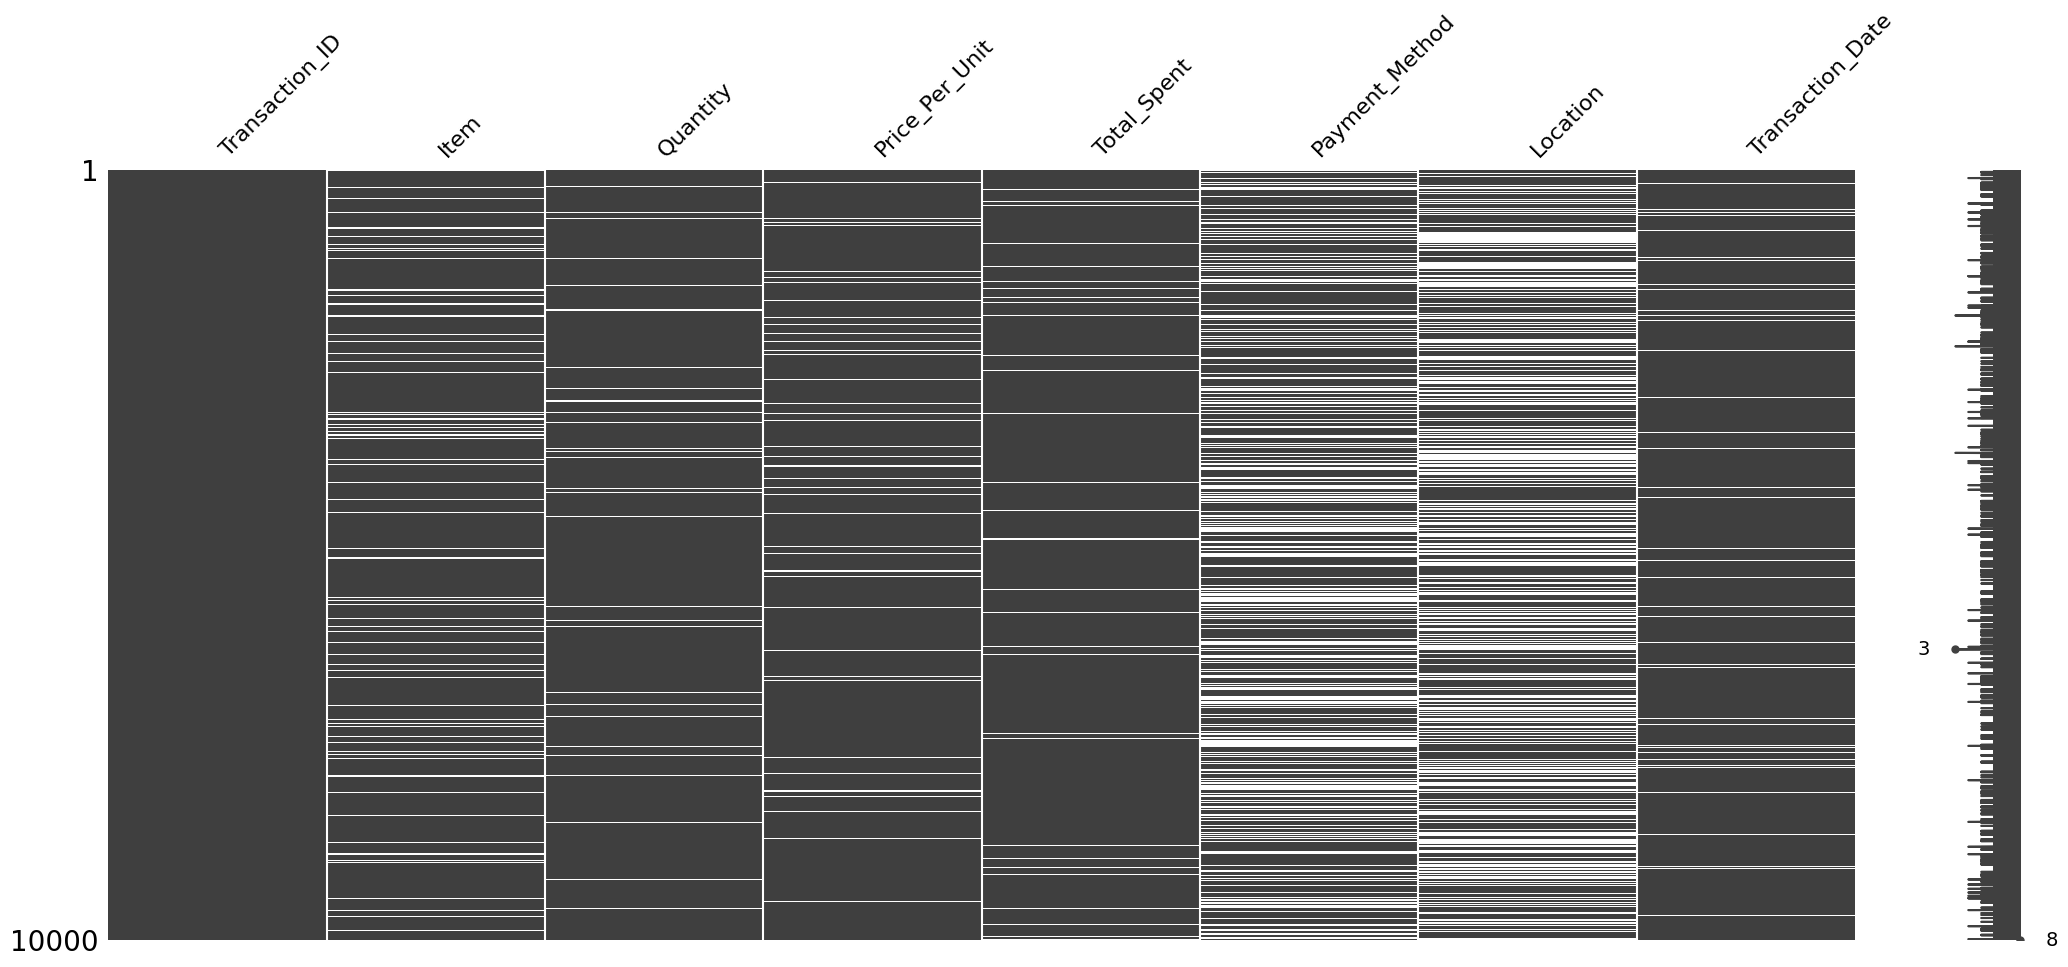

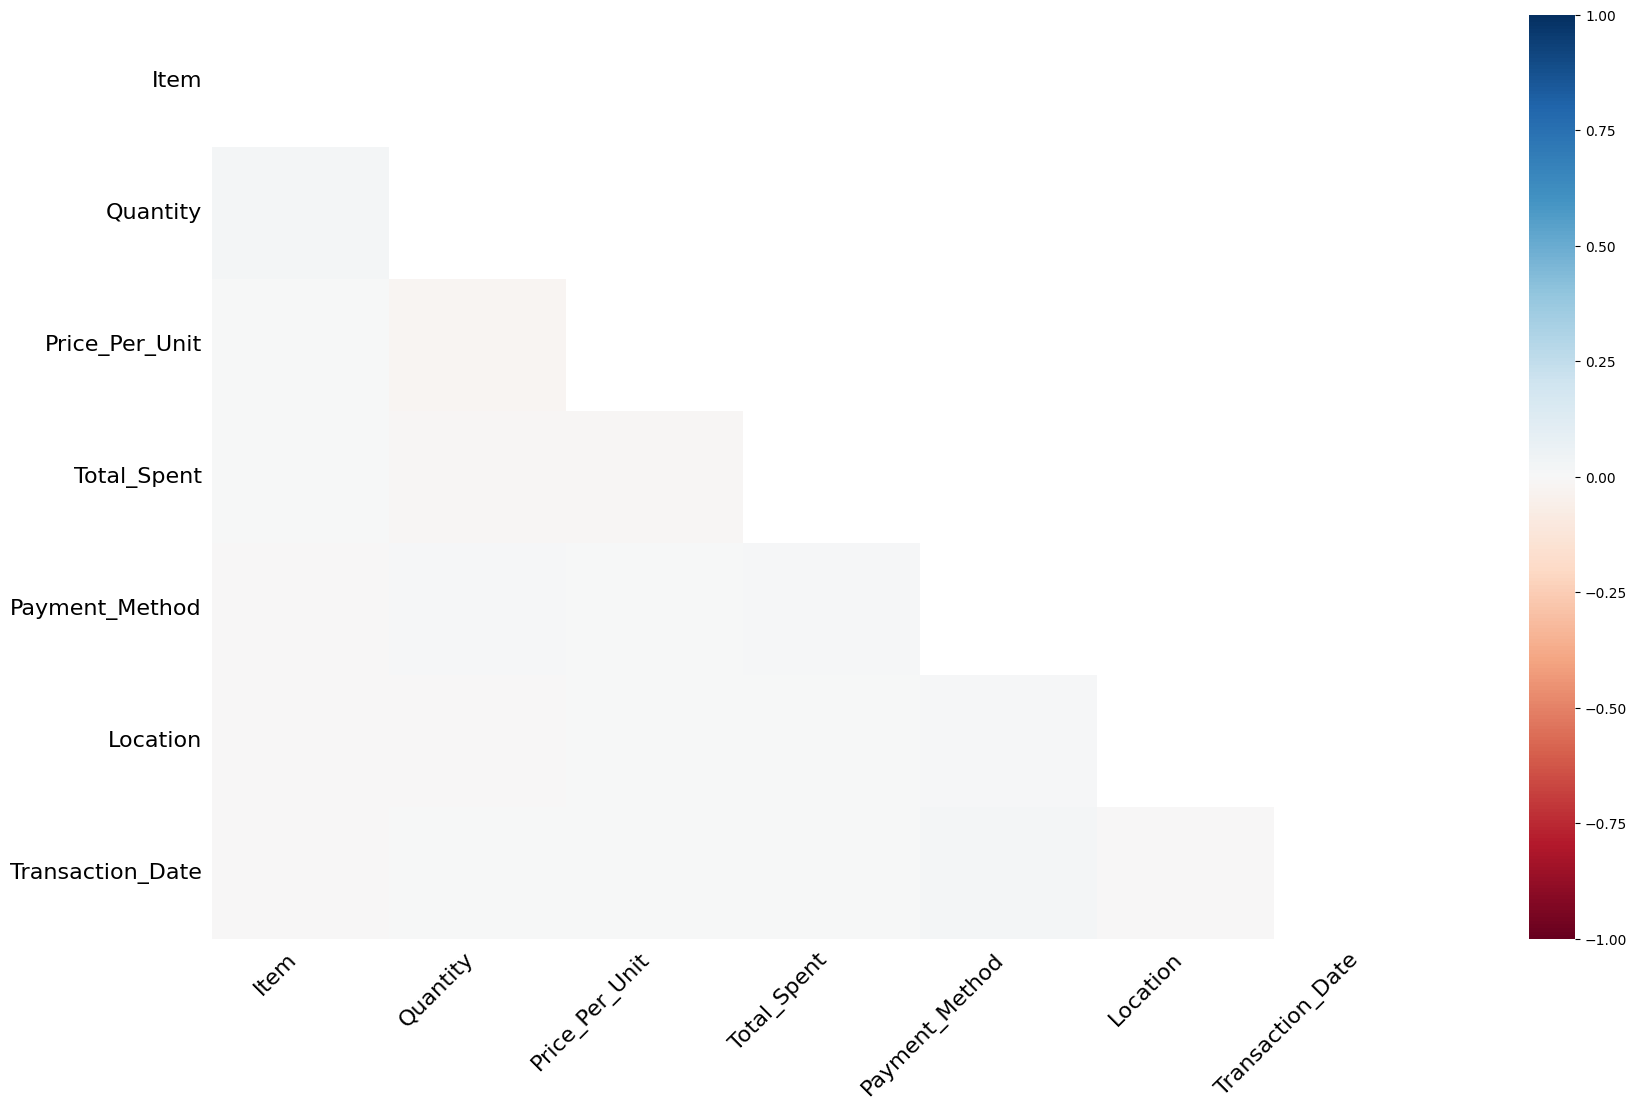

In [35]:
#look at the missing values with different visuals to see if there are any correlations between missing values

msno.matrix(df1)      
msno.heatmap(df1)      


In [36]:
# Fill the Price Per Unit category.
"""
This block of code tries to fill the price per unit category by calculating it if possible and imputing
it if it isn't possible. To do this, it checks if the PPU is there. If not, tries to calculate the PPU by dividing the
Total Spend by the Quantity of items purchased.

If it can't do this because quantity of items is missing, it finds all the possible prices it could be from Total Spend.
Total Spend is always a multiple of the PPU because it only accounts for the purchasing of some amount of a single item.
The code then takes the mode of the column if it is indeed possible that the mode could be the PPU for the given Total Spend,
otherwise, it will just take whatever valid value works.

If Total Spend is also missing, the mode used.
"""
ppu_mode = df1['Price_Per_Unit'].mode()[0]
prices = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0]


def find_ppu(row):
    #if PPU already exists, keep it
    if pd.notna(row['Price_Per_Unit']):
        return row['Price_Per_Unit']

    # if total spend and quantity exist, calculate PPU
    if pd.notna(row['Total_Spent']) and pd.notna(row['Quantity']):
        return row['Total_Spent'] / row['Quantity']

    # if only total spend exists, we need to find a suitable value for PPU
    if pd.notna(row['Total_Spent']):

        valid_divisors = [p for p in prices if (np.isclose(row['Total_Spent'] % p, 0))]

        if valid_divisors:
            # take the mode if possible, otherwise, take whichever other divisor works
            if ppu_mode in valid_divisors:
                return ppu_mode
            else:
                return valid_divisors[random.randint(0,len(valid_divisors) - 1)]
    #if we have nothing else, use mode
    return ppu_mode
            
df1['Price_Per_Unit'] = df1.apply(find_ppu, axis = 1)




#double check
print(df1['Price_Per_Unit'].value_counts())
print(df1['Price_Per_Unit'].isna().sum())

Price_Per_Unit
3.0    2579
4.0    2445
2.0    1290
5.0    1272
1.0    1213
1.5    1201
Name: count, dtype: int64
0


In [37]:
"""
To fill Item, we create a matching function that will assign values to item based on the given price.
We don't know which of the items were one of the two options for $3 and $4, but the matching function will switch 
once half of the values have been filled, which should be meaningfully close enough. 

To avoid accidently overwritting an existing entry, we use a new series (missing_item_mask) that stops the apply function from running
on any entry that wasn't missing a item value. 
"""


def item_clean(val):
    
    match val:
        case 1.0: return 'Cookie'
        case 1.5: return 'Tea'
        case 2.0: return 'Coffee'
        case 3.0:
            if (df1['Item'] == 'Juice').sum() > (len(df1) / 2) :
                return 'Cake'
            return 'Juice'
        case 4.0:
            if (df1['Item'] == 'Smoothie').sum() > (len(df1) / 2) :
                return 'Sandwich'
            return 'Smoothie'
        case 5.0: return 'Salad'
        case _: return 'Unknown'

missing_item_mask = df1['Item'].isna()
df1.loc[missing_item_mask, 'Item'] = df1.loc[missing_item_mask, 'Price_Per_Unit'].apply(item_clean)

#double check
print(df1['Item'].value_counts())
print(df1['Item'].isna().sum())

Item
Juice       1422
Smoothie    1323
Coffee      1291
Salad       1273
Cookie      1214
Tea         1207
Cake        1139
Sandwich    1131
Name: count, dtype: int64
0


In [38]:
# Fill the quantity based on total spend and PPU
# If we still don't know total spend, fill it based on the mode of quantity

df1['Quantity'] = df1['Quantity'].fillna(df1['Total_Spent'] / df1['Price_Per_Unit']).fillna(df1['Quantity'].mode()[0])

#double check
print(df1['Quantity'].isna().sum())

0


In [39]:
# Fill Total Spent using the calculations from quantity and PPU

df1['Total_Spent'] = df1['Total_Spent'].fillna(df1['Quantity'] * df1['Price_Per_Unit'])

#double check
print(df1['Total_Spent'].isna().sum())

0


In [40]:
df1.head()

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [41]:
"""
We now must fill Payment Method, Location, and Transaction Date Columns. Check the amount of missing values.
If they are above 40%, we drop the column entirely (too much missing data makes finding useful information difficult).
"""

print(df1['Payment_Method'].isna().sum() / len(df1))
print(df1['Transaction_Date'].isna().sum() / len(df1))
print(df1['Location'].isna().sum() / len(df1))

0.3178
0.046
0.3961


In [42]:
#check value counts
df1['Payment_Method'].value_counts()


Payment_Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

In [43]:
"""
Because there are so many missing values and this is a categorical column with even values,
we use proportional imputation with random generation to get an accurate result.
"""

#set seed for reproducibilty
seed = 12345

def proportional_impute(series, seed):

    rng = np.random.default_rng(seed)
    
    #get the distribution of non na values
    observed = series.dropna()
    value_counts = observed.value_counts(normalize = True)

    categories = value_counts.index.to_numpy()
    probabilities = value_counts.values

    #get number of missing values
    n_missing = series.isnull().sum()

    #sample replacement based on collected info
    fill_values = rng.choice(categories, size = n_missing, p = probabilities)

    result = series.copy()
    result.loc[result.isnull()] = fill_values
    return result

df1['Payment_Method'] = proportional_impute(df1['Payment_Method'], seed)

#double check
print(df1['Payment_Method'].isna().sum())
print(df1['Payment_Method'].value_counts())

0
Payment_Method
Digital Wallet    3379
Credit Card       3342
Cash              3279
Name: count, dtype: int64


In [44]:
#check value counts
df1['Location'].value_counts()

Location
Takeaway    3022
In-store    3017
Name: count, dtype: int64

In [45]:
"""
We can use the function again for the location column.
"""
df1['Location'] = proportional_impute(df1['Location'], seed)

#double check
print(df1['Location'].isna().sum())
print(df1['Location'].value_counts())

0
Location
Takeaway    5040
In-store    4960
Name: count, dtype: int64


In [46]:
df1.head()

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,Digital Wallet,Takeaway,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [47]:
#forward fill to impute the last column
df1['Transaction_Date'] = df1['Transaction_Date'].ffill() 

#double check
print(df1['Location'].isna().sum())
date_range = df1['Transaction_Date'].agg(['min','max'])
print(date_range)

0
min   2023-01-01
max   2023-12-31
Name: Transaction_Date, dtype: datetime64[ns]


In [48]:
#check for outliers

fig = px.box(df1, y="Quantity")
fig.show()

In [49]:
fig = px.box(df1, y="Total_Spent")
fig.show()

In [50]:
df1.loc[df1['Quantity'] > 5]

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
912,TXN_1575608,Sandwich,10.0,2.0,20.0,Digital Wallet,Takeaway,2023-01-05
1482,TXN_3593060,Smoothie,16.0,1.0,16.0,Cash,In-store,2023-03-05
9819,TXN_1208561,Cookie,20.0,1.0,20.0,Credit Card,In-store,2023-08-19


In [51]:
df1.loc[df1['Total_Spent'] > 20]

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
10,TXN_2548360,Salad,5.0,5.0,25.0,Cash,Takeaway,2023-11-07
51,TXN_6342161,Salad,5.0,5.0,25.0,Digital Wallet,Takeaway,2023-01-08
52,TXN_8914892,Salad,5.0,5.0,25.0,Digital Wallet,In-store,2023-03-15
96,TXN_5220895,Salad,5.0,5.0,25.0,Cash,In-store,2023-06-10
100,TXN_9517146,Salad,5.0,5.0,25.0,Cash,Takeaway,2023-10-30
...,...,...,...,...,...,...,...,...
9791,TXN_1232346,Salad,5.0,5.0,25.0,Digital Wallet,In-store,2023-01-04
9805,TXN_9506076,Salad,5.0,5.0,25.0,Credit Card,Takeaway,2023-01-17
9879,TXN_6393305,Salad,5.0,5.0,25.0,Digital Wallet,In-store,2023-10-19
9908,TXN_8922585,Salad,5.0,5.0,25.0,Credit Card,Takeaway,2023-06-22


In [52]:
#export the finished file
#this file is already provided to you. If you would like a fresh copy, remove the '#' character from the line
# of code below and run this cell by pressing the play button or hitting 'Shift + Enter'

# df1.to_csv('cleaned_cafe_sales.csv', index=False)